# Student Performance Prediction

This notebook builds a small, reproducible regression workflow to estimate students' final mathematics grade (`G3`) from the UCI Student Performance dataset. It demonstrates data checks, exploratory analysis, preprocessing, a baseline, a random-forest model, and held-out evaluation.

**Prediction is not causation.** The model can identify patterns useful for prediction in this dataset; it cannot show that any student characteristic causes a higher or lower grade. Use predictions as an educational exercise, not to make decisions about individual students.

## Dataset and prediction target

We use the **Math course** file (`student-mat.csv`) from the [UCI Student Performance dataset](https://archive.ics.uci.edu/dataset/320/student+performance). The notebook downloads the official UCI ZIP archive and reads the CSV directly from memory; it does not save a dataset copy.

The target is final grade `G3` (0-20). Earlier grades `G1` and `G2` are retained as predictors, which makes this a prediction after those grading periods. Their strong relationship to `G3` may not be available for an earlier-intervention use case. This dataset is a small sample from two Portuguese schools and is not representative of every school or student population.

In [10]:
from io import BytesIO
from urllib.error import HTTPError, URLError
from urllib.request import urlopen
from zipfile import ZipFile
import math

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
TARGET = "G3"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)

## Load the dataset

The official download is attempted when this cell runs. If the service is unavailable, the raised error identifies the URL rather than substituting another dataset or generating sample data.

In [11]:

try:
    with urlopen(DATA_URL, timeout=30) as response:
        archive_bytes = response.read()
except (HTTPError, URLError, TimeoutError) as error:
    raise RuntimeError(
        f"Could not download the UCI dataset from {DATA_URL}. "
        "Check your internet connection and try again."
    ) from error

def load_student_csv(zip_bytes):
    with ZipFile(BytesIO(zip_bytes)) as archive:
        for name in archive.namelist():
            if name.lower().replace("\\", "/").endswith("student-mat.csv"):
                with archive.open(name) as csv_file:
                    return pd.read_csv(csv_file, sep=";"), name

        # The CSV may be inside a nested ZIP.
        for name in archive.namelist():
            if name.lower().endswith(".zip"):
                with archive.open(name) as nested_file:
                    try:
                        return load_student_csv(nested_file.read())
                    except (FileNotFoundError, BadZipFile):
                        continue

    raise FileNotFoundError(
        "student-mat.csv was not found in the downloaded ZIP archives."
    )

df, csv_path = load_student_csv(archive_bytes)

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {csv_path}.")
df.head()


Loaded 395 rows and 33 columns from student-mat.csv.


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## Data quality and structure

Review the table shape, data types, missing values, duplicate rows, and grade ranges before modeling. These checks describe this downloaded sample; they do not guarantee that future data will have the same quality.

In [12]:
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values").T)
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print("\nNumeric summary:")
display(df.describe().T)

if TARGET not in df.columns:
    raise ValueError(f"Expected target column {TARGET!r} was not found.")
print(f"\n{TARGET} range: {df[TARGET].min()} to {df[TARGET].max()}")
print("Final grade counts:")
display(df[TARGET].value_counts().sort_index().to_frame("students"))

Shape: (395, 33)

Data types:


,dtype
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


Missing values by column:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
missing_values,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Exact duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0



G3 range: 0 to 20
Final grade counts:


,students
G3,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47


## Exploratory data analysis

These plots summarize observed associations in the sample. They are descriptive and should not be interpreted as evidence of cause and effect.

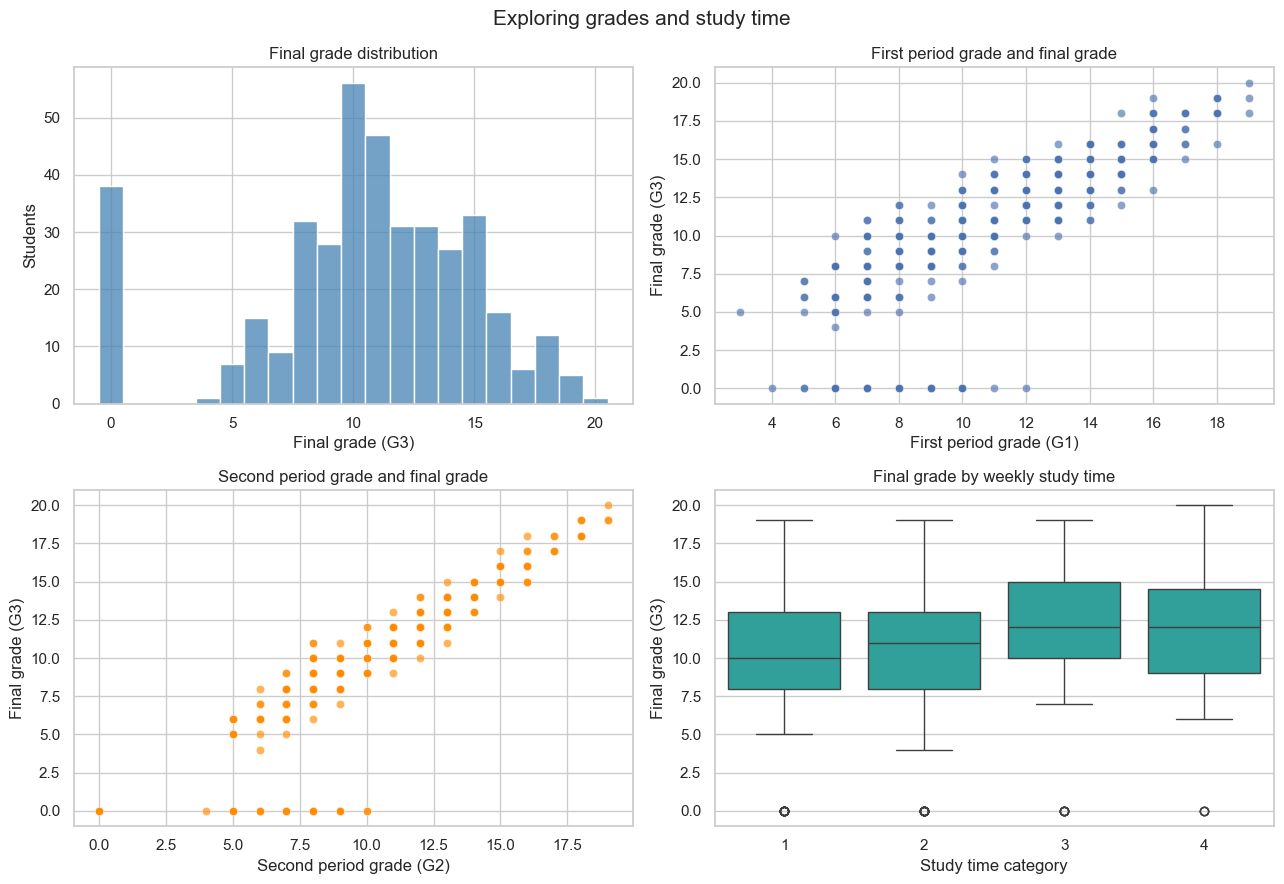

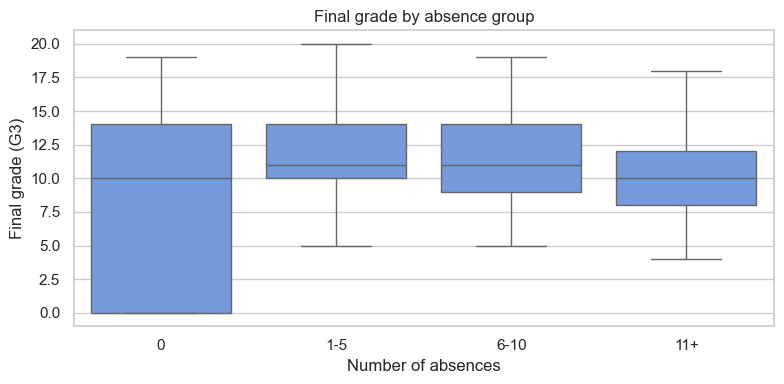

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(data=df, x=TARGET, bins=21, discrete=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set(title="Final grade distribution", xlabel="Final grade (G3)", ylabel="Students")

sns.scatterplot(data=df, x="G1", y=TARGET, alpha=0.65, ax=axes[0, 1])
axes[0, 1].set(title="First period grade and final grade", xlabel="First period grade (G1)", ylabel="Final grade (G3)")

sns.scatterplot(data=df, x="G2", y=TARGET, alpha=0.65, ax=axes[1, 0], color="darkorange")
axes[1, 0].set(title="Second period grade and final grade", xlabel="Second period grade (G2)", ylabel="Final grade (G3)")

sns.boxplot(data=df, x="studytime", y=TARGET, ax=axes[1, 1], color="lightseagreen")
axes[1, 1].set(title="Final grade by weekly study time", xlabel="Study time category", ylabel="Final grade (G3)")

fig.suptitle("Exploring grades and study time", fontsize=15)
fig.tight_layout()
plt.show()

absence_plot = df.assign(
    absence_group=pd.cut(
        df["absences"],
        bins=[-1, 0, 5, 10, float("inf")],
        labels=["0", "1-5", "6-10", "11+"],
    )
)
plt.figure(figsize=(8, 4))
sns.boxplot(data=absence_plot, x="absence_group", y=TARGET, color="cornflowerblue")
plt.title("Final grade by absence group")
plt.xlabel("Number of absences")
plt.ylabel("Final grade (G3)")
plt.tight_layout()
plt.show()

## Split and preprocess

We hold out a test set before fitting any transformations. Numeric features are standardized and categorical features are one-hot encoded within a scikit-learn pipeline, so preprocessing is learned from training data only. The random split is for a simple demonstration, not a guarantee of unbiased evaluation for other schools or future cohorts.

In [14]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Numeric features: {len(numeric_features)} | Categorical features: {len(categorical_features)}")

Training rows: 316 | Test rows: 79
Numeric features: 15 | Categorical features: 17


## Baseline and prediction model

The baseline always predicts the training-set mean. We compare it with a random forest, which can capture non-linear patterns and interactions. Both are evaluated on the same untouched test rows.

In [15]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]
)
model.fit(X_train, y_train)
model_predictions = model.predict(X_test)

print("Both models fitted. Predictions were made for the held-out test set.")

Both models fitted. Predictions were made for the held-out test set.


## Evaluation

Mean absolute error (MAE) and root mean squared error (RMSE) are in grade points; lower is better. R-squared summarizes variance explained relative to a constant-mean prediction and can be negative on a test set. Metrics describe this particular split and are not guarantees of future performance.

In [16]:
def regression_metrics(actual, predicted):
    return {
        "MAE (grade points)": mean_absolute_error(actual, predicted),
        "RMSE (grade points)": math.sqrt(mean_squared_error(actual, predicted)),
        "R-squared": r2_score(actual, predicted),
    }

results = pd.DataFrame(
    {
        "Mean baseline": regression_metrics(y_test, baseline_predictions),
        "Random forest": regression_metrics(y_test, model_predictions),
    }
).T
display(results.round(3))

,MAE (grade points),RMSE (grade points),R-squared
Mean baseline,3.646,4.550,-0.010
Random forest,1.216,2.033,0.799


In [23]:

# Experiment: Predict final grades without G1 and G2

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import math
import pandas as pd

# Remove earlier grades from the features
X_train_no_grades = X_train.drop(columns=["G1", "G2"])
X_test_no_grades = X_test.drop(columns=["G1", "G2"])

# Identify numeric and categorical columns
numeric_features = X_train_no_grades.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train_no_grades.select_dtypes(
    exclude="number"
).columns.tolist()

# Build a new preprocessor using only the remaining features
preprocessor_no_grades = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
    ]
)

# Build a separate model; do not modify the original model
model_no_grades = Pipeline(
    steps=[
        ("preprocessor", preprocessor_no_grades),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

# Train and predict
model_no_grades.fit(X_train_no_grades, y_train)
predictions_no_grades = model_no_grades.predict(X_test_no_grades)

# Compare performance on the same test set
comparison = pd.DataFrame(
    {
        "With G1 and G2": regression_metrics(
            y_test, model_predictions
        ),
        "Without G1 and G2": regression_metrics(
            y_test, predictions_no_grades
        ),
    }
).T

display(comparison.round(3))



,MAE (grade points),RMSE (grade points),R-squared
With G1 and G2,1.216,2.033,0.799
Without G1 and G2,3.010,3.765,0.309


In [22]:

print("Pipeline steps:")
for name, step in model.named_steps.items():
    print(f"\n{name}: {type(step).__name__}")
    if hasattr(step, "transformers"):
        print("Transformers:", step.transformers)
    if hasattr(step, "feature_names_in_"):
        print("Expected features:", step.feature_names_in_.tolist())


Pipeline steps:

preprocessor: ColumnTransformer
Transformers: [('numeric', StandardScaler(), ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']), ('categorical', OneHotEncoder(handle_unknown='ignore'), ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic'])]
Expected features: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

regressor: RandomForestRegressor


In [19]:

print("X_train columns:")
print(X_train.columns.tolist())

print("\nOriginal model type:")
print(type(model).__name__)

print("\nOriginal model feature count:")
print(model.n_features_in_)


X_train columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Original model type:
Pipeline

Original model feature count:
32


## Interpretation

Feature importance here measures how much the fitted random forest used each encoded feature to reduce its training error. It is a model-specific predictive summary, can be biased or unstable, and does **not** estimate a causal effect or explain why a student earned a particular grade.

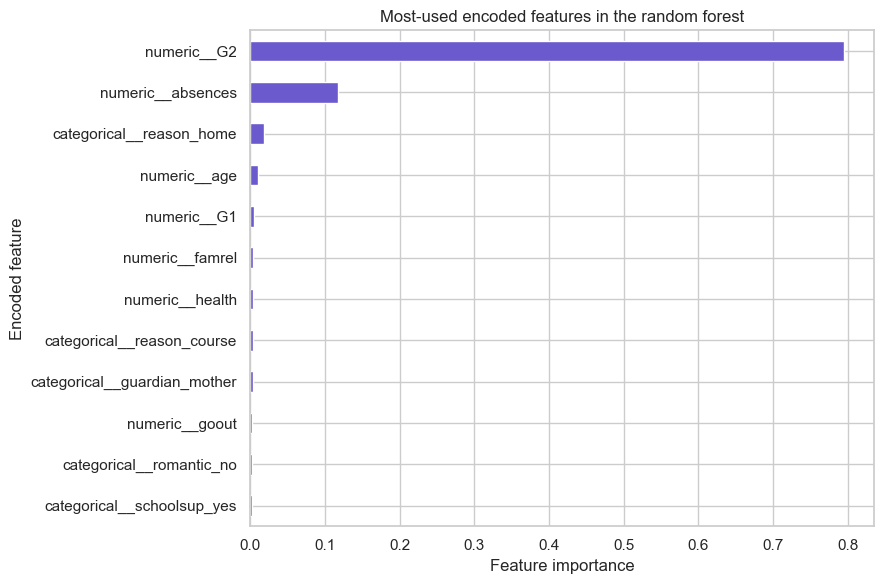

,importance
numeric__G2,0.795710
numeric__absences,0.116984
categorical__reason_home,0.017763
numeric__age,0.009912
numeric__G1,0.005021
numeric__famrel,0.004085
numeric__health,0.003943
categorical__reason_course,0.003816
categorical__guardian_mother,0.003556
numeric__goout,0.002681


In [17]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(
    model.named_steps["regressor"].feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

top_importance = importance.head(12).sort_values()
plt.figure(figsize=(9, 6))
top_importance.plot(kind="barh", color="slateblue")
plt.title("Most-used encoded features in the random forest")
plt.xlabel("Feature importance")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

display(importance.head(12).to_frame("importance"))

## Limitations and responsible use

- The data cover 395 students from two Portuguese schools in a particular period; performance may differ across places, cohorts, and grading systems.
- `G1` and `G2` are earlier grades that overlap closely with the target `G3`. This model therefore predicts final grades late in the course, not from only early background information.
- A single random train/test split is small and can give variable results. A stronger study would use repeated or time-based validation and an external dataset.
- Survey measures and school records may be noisy, incomplete, or shaped by context not represented in the data.
- Feature importance and observed correlations are not causal evidence. This analysis cannot establish why students perform well or poorly.
- Predictions can be wrong and could reproduce patterns in the sample. Do not use this demonstration to label, rank, or make high-stakes decisions about students.

**Conclusion:** The notebook compares a simple benchmark with one prediction model on one held-out sample. Any apparent performance advantage is limited to this setup and should not be treated as proof of general effectiveness or of causal explanations.